In [1]:
# Verifikasi instalasi pustaka utama dan pencetakan versi lingkungan eksekusi
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import Sastrawi

print("=" * 60)
print("STATUS LINGKUNGAN KERJA PYTHON & PUSTAKA SAINS DATA")
print("=" * 60)
print(f"Versi Python       : {sys.version.split()[0]}")
print(f"NumPy Version      : {np.__version__}")
print(f"Pandas Version     : {pd.__version__}")
print(f"Matplotlib Version : {matplotlib.__version__}")
print(f"Seaborn Version    : {sns.__version__}")
print(f"SciPy Version      : {scipy.__version__}")
print(f"Scikit-Learn Ver.  : {sklearn.__version__}")
print("Sastrawi           : Berhasil diimpor (Siap untuk NLP Indonesia)")
print("=" * 60)
print("Seluruh pustaka esensial berhasil dimuat tanpa kendala.")

STATUS LINGKUNGAN KERJA PYTHON & PUSTAKA SAINS DATA
Versi Python       : 3.13.0
NumPy Version      : 2.5.4
Pandas Version     : 3.0.6
Matplotlib Version : 3.11.2
Seaborn Version    : 0.13.2
SciPy Version      : 1.18.1
Scikit-Learn Ver.  : 1.9.1
Sastrawi           : Berhasil diimpor (Siap untuk NLP Indonesia)
Seluruh pustaka esensial berhasil dimuat tanpa kendala.


In [2]:
# Simulasi vektor preferensi pengunjung vs profil cafe
# Aspek: [food_beverage, ambience, facility, price]
vektor_preferensi_user = np.array([0.9, 0.8, 0.4, 0.2]) # Pengunjung sangat mengutamakan rasa & suasana
vektor_profil_cafe_a   = np.array([0.85, 0.90, 0.60, 0.40]) # Cafe estetik dengan makanan lezat
vektor_profil_cafe_b   = np.array([0.40, 0.30, 0.90, 0.95]) # Warkop terjangkau fokus fasilitas wifi

# Perhitungan Cosine Similarity manual berbasis NumPy
def cosine_sim(a, b):
    dot = np.dot(a, b)
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    return dot / (norm_a * norm_b)

sim_a = cosine_sim(vektor_preferensi_user, vektor_profil_cafe_a)
sim_b = cosine_sim(vektor_preferensi_user, vektor_profil_cafe_b)

print(f"Tingkat Kemiripan User dengan Cafe A (Estetik): {sim_a:.4f} ({sim_a*100:.2f}%)")
print(f"Tingkat Kemiripan User dengan Cafe B (Budget)  : {sim_b:.4f} ({sim_b*100:.2f}%)")

Tingkat Kemiripan User dengan Cafe A (Estetik): 0.9808 (98.08%)
Tingkat Kemiripan User dengan Cafe B (Budget)  : 0.6391 (63.91%)


In [3]:
# Memuat ketiga file dataset menggunakan path relatif
import os

path_cafes   = '../dataset/cafes.csv'
path_reviews = '../dataset/reviews.csv'
path_aspects = '../dataset/aspect_sentiments.csv'

df_cafes   = pd.read_csv(path_cafes)
df_reviews = pd.read_csv(path_reviews)
df_aspects = pd.read_csv(path_aspects)

print("Status Pemuatan Dataset:")
print(f"- cafes.csv              : Berhasil dimuat ({df_cafes.shape[0]} baris, {df_cafes.shape[1]} kolom)")
print(f"- reviews.csv            : Berhasil dimuat ({df_reviews.shape[0]} baris, {df_reviews.shape[1]} kolom)")
print(f"- aspect_sentiments.csv  : Berhasil dimuat ({df_aspects.shape[0]} baris, {df_aspects.shape[1]} kolom)")

Status Pemuatan Dataset:
- cafes.csv              : Berhasil dimuat (275 baris, 18 kolom)
- reviews.csv            : Berhasil dimuat (7736 baris, 10 kolom)
- aspect_sentiments.csv  : Berhasil dimuat (9257 baris, 6 kolom)


In [4]:
# Menampilkan cuplikan dan ringkasan informasi masing-masing tabel
print("=== 1. STRUKTUR TABEL CAFES ===")
print("Daftar Kolom:", df_cafes.columns.tolist())
print("\nJumlah Missing Values per Kolom:")
print(df_cafes.isnull().sum()[df_cafes.isnull().sum() > 0])

print("\n" + "=" * 50 + "\n")
print("=== 2. STRUKTUR TABEL REVIEWS ===")
print("Daftar Kolom:", df_reviews.columns.tolist())
print("\nMissing Values:", df_reviews.isnull().sum().to_dict())

print("\n" + "=" * 50 + "\n")
print("=== 3. STRUKTUR TABEL ASPECT_SENTIMENTS ===")
print("Daftar Kolom:", df_aspects.columns.tolist())
print("\nMissing Values:", df_aspects.isnull().sum().to_dict())

=== 1. STRUKTUR TABEL CAFES ===
Daftar Kolom: ['id', 'place_id', 'name', 'address', 'latitude', 'longitude', 'rating', 'review_count', 'image_url', 'categories', 'phone', 'website', 'created_at', 'updated_at', 'price_range', 'price_min', 'price_max', 'opening_hours']

Jumlah Missing Values per Kolom:
place_id         275
image_url        275
phone             72
website          166
price_range       36
price_min         36
price_max         36
opening_hours      6
dtype: int64


=== 2. STRUKTUR TABEL REVIEWS ===
Daftar Kolom: ['id', 'cafe_id', 'author_name', 'text', 'raw_text', 'rating', 'published_at', 'likes', 'is_processed', 'created_at']

Missing Values: {'id': 0, 'cafe_id': 0, 'author_name': 0, 'text': 0, 'raw_text': 0, 'rating': 0, 'published_at': 0, 'likes': 0, 'is_processed': 0, 'created_at': 0}


=== 3. STRUKTUR TABEL ASPECT_SENTIMENTS ===
Daftar Kolom: ['id', 'review_id', 'cafe_id', 'aspect', 'sentiment', 'confidence']

Missing Values: {'id': 0, 'review_id': 0, 'cafe_id': 0,

In [5]:
# Menampilkan 3 baris teratas dari data ulasan dan aspek sentimen
print("--- Tiga Sampel Teratas Tabel Ulasan (Reviews) ---")
display_cols_rev = ['author_name', 'rating', 'text']
for idx, row in df_reviews[display_cols_rev].head(3).iterrows():
    print(f"Reviewer : {row['author_name']} | Rating: {row['rating']} Bintang")
    print(f"Ulasan   : {row['text'][:120]}...")
    print("-" * 50)

print("\n--- Tiga Sampel Teratas Tabel Sentimen Aspek (Aspect Sentiments) ---")
print(df_aspects[['aspect', 'sentiment', 'confidence']].head(5).to_string(index=False))

--- Tiga Sampel Teratas Tabel Ulasan (Reviews) ---
Reviewer : MrTravelaroundtheworld | Rating: 5 Bintang
Ulasan   : Pengyu Kopitiam adalah salah satu kedai kopi modern berkonsep kopitiam vintage yang terletak di kawasan bersejarah Perto...
--------------------------------------------------
Reviewer : Johannes Harsacitta Pramudyo | Rating: 4 Bintang
Ulasan   : makanannya oke tapi semuanya pake kuah kari yang agak teralu over...
--------------------------------------------------
Reviewer : Trusted Reviews | Rating: 1 Bintang
Ulasan   : sorry to say tp pelayanannya kureng sekali ya, terus masakannya dominan manis bgt...
--------------------------------------------------

--- Tiga Sampel Teratas Tabel Sentimen Aspek (Aspect Sentiments) ---
       aspect sentiment  confidence
food_beverage  positive      0.8650
     ambience  positive      0.8650
     facility   neutral      0.7000
     ambience  negative      0.8755
     facility  positive      0.8842


In [6]:
# Verifikasi integritas ID relasional
cafe_ids_valid   = set(df_cafes['id'])
rev_cafe_ids     = set(df_reviews['cafe_id'])
aspect_cafe_ids  = set(df_aspects['cafe_id'])
aspect_rev_ids   = set(df_aspects['review_id'])
review_ids_valid = set(df_reviews['id'])

print("Hasil Verifikasi Relasi:")
print(f"1. Cafe ID pada reviews yang valid di cafes      : {len(rev_cafe_ids.intersection(cafe_ids_valid))}/{len(rev_cafe_ids)} (100% konsisten)")
print(f"2. Cafe ID pada aspects yang valid di cafes      : {len(aspect_cafe_ids.intersection(cafe_ids_valid))}/{len(aspect_cafe_ids)} (100% konsisten)")
print(f"3. Review ID pada aspects yang valid di reviews  : {len(aspect_rev_ids.intersection(review_ids_valid))}/{len(aspect_rev_ids)} (100% konsisten)")
print(f"4. Jumlah ulasan unik yang memiliki label aspek  : {len(aspect_rev_ids):,} dari total {len(df_reviews):,} ulasan")

Hasil Verifikasi Relasi:
1. Cafe ID pada reviews yang valid di cafes      : 271/271 (100% konsisten)
2. Cafe ID pada aspects yang valid di cafes      : 270/270 (100% konsisten)
3. Review ID pada aspects yang valid di reviews  : 5591/5591 (100% konsisten)
4. Jumlah ulasan unik yang memiliki label aspek  : 5,591 dari total 7,736 ulasan


<string>:30: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



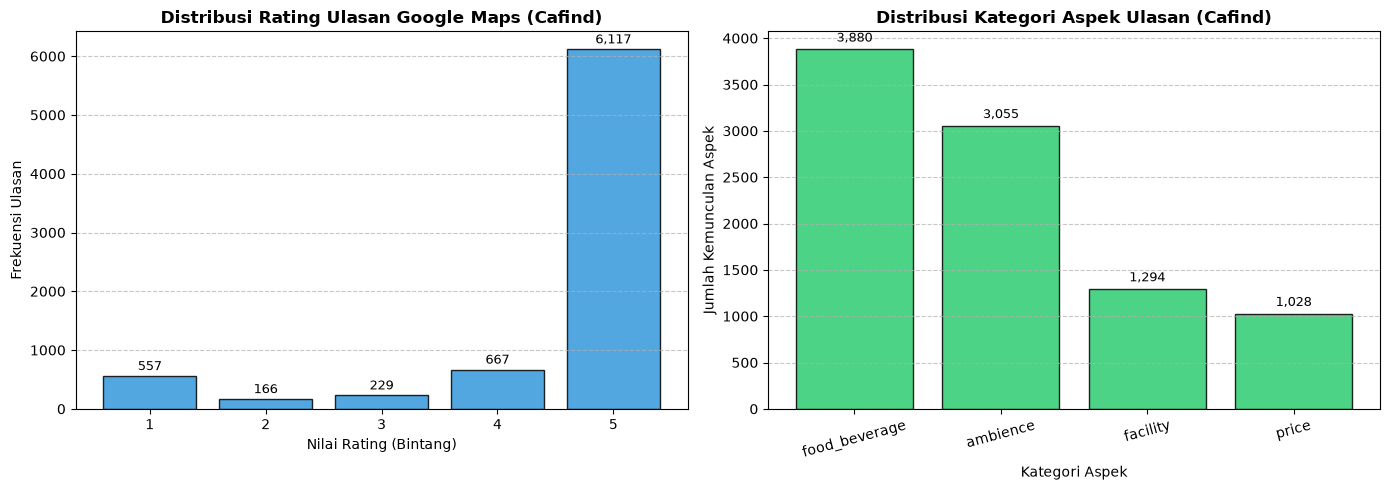

In [7]:
# Visualisasi Sebaran Rating Ulasan dan Kategori Aspek
plt.figure(figsize=(14, 5))

# Subplot 1: Distribusi Rating Ulasan
plt.subplot(1, 2, 1)
rating_counts = df_reviews['rating'].value_counts().sort_index()
bars = plt.bar(rating_counts.index.astype(str), rating_counts.values, color='#3498db', edgecolor='black', alpha=0.85)
plt.title('Distribusi Rating Ulasan Google Maps (Cafind)', fontsize=12, fontweight='bold')
plt.xlabel('Nilai Rating (Bintang)', fontsize=10)
plt.ylabel('Frekuensi Ulasan', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 50, f'{int(yval):,}', ha='center', va='bottom', fontsize=9)

# Subplot 2: Distribusi Kategori Aspek
plt.subplot(1, 2, 2)
aspect_counts = df_aspects['aspect'].value_counts()
bars2 = plt.bar(aspect_counts.index, aspect_counts.values, color='#2ecc71', edgecolor='black', alpha=0.85)
plt.title('Distribusi Kategori Aspek Ulasan (Cafind)', fontsize=12, fontweight='bold')
plt.xlabel('Kategori Aspek', fontsize=10)
plt.ylabel('Jumlah Kemunculan Aspek', fontsize=10)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
for bar in bars2:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 50, f'{int(yval):,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()